**GitHub Username:** zl535992549-cell

**USC ID:** 8768388438

## 1.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, roc_curve, roc_auc_score, accuracy_score
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline as SkPipeline
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from xgboost import XGBClassifier

RANDOM_STATE = 42
get_ipython().run_line_magic('matplotlib', 'inline')

### (a)

In [ ]:
train = pd.read_csv('../data/aps_failure_training_set.csv', skiprows=20, na_values='na')
test = pd.read_csv('../data/aps_failure_test_set.csv', skiprows=20, na_values='na')
X_train_raw = train.drop(columns='class')
X_test_raw = test.drop(columns='class')
y_train = (train['class'] == 'pos').astype(int)
y_test = (test['class'] == 'pos').astype(int)
print('Training:', X_train_raw.shape, ' Test:', X_test_raw.shape)
print('Missing training values:', int(X_train_raw.isna().sum().sum()))

Training: (60000, 170)  Test: (16000, 170)
Missing training values: 850015


### (b)(i)

Missing values are imputed using the training median.

In [ ]:
imputer = SimpleImputer(strategy='median')
X_train = pd.DataFrame(imputer.fit_transform(X_train_raw), columns=X_train_raw.columns)
X_test = pd.DataFrame(imputer.transform(X_test_raw), columns=X_train_raw.columns)
print('Missing after imputation:', int(X_train.isna().sum().sum()), int(X_test.isna().sum().sum()))

Missing after imputation: 0 0


### (b)(ii)

In [ ]:
cv = X_train.std(ddof=1) / X_train.mean().replace(0, np.nan)
cv = cv.replace([np.inf, -np.inf], np.nan)
items = [f'{name}: {value:.2f}' for name, value in cv.items()]
for i in range(0, len(items), 5):
    print('    '.join(items[i:i + 5]))

aa_000: 2.45    ab_000: 10.38    ac_000: 2.31    ad_000: 244.32    ae_000: 24.20
af_000: 19.47    ag_000: 92.92    ag_001: 35.25    ag_002: 17.57    ag_003: 8.65
ag_004: 5.46    ag_005: 2.96    ag_006: 2.36    ag_007: 2.86    ag_008: 6.22
ag_009: 33.36    ah_000: 2.31    ai_000: 18.20    aj_000: 44.27    ak_000: 80.42
al_000: 9.17    am_0: 9.16    an_000: 2.25    ao_000: 2.27    ap_000: 3.08
aq_000: 2.86    ar_000: 11.35    as_000: 87.33    at_000: 23.71    au_000: 68.88
av_000: 6.01    ax_000: 4.02    ay_000: 37.43    ay_001: 52.82    ay_002: 39.25
ay_003: 28.74    ay_004: 33.75    ay_005: 12.52    ay_006: 3.05    ay_007: 3.31
ay_008: 3.82    ay_009: 84.73    az_000: 9.41    az_001: 7.72    az_002: 13.27
az_003: 7.53    az_004: 2.85    az_005: 3.03    az_006: 8.88    az_007: 16.23
az_008: 22.68    az_009: 77.84    ba_000: 2.70    ba_001: 2.62    ba_002: 2.90
ba_003: 2.73    ba_004: 2.63    ba_005: 2.70    ba_006: 3.03    ba_007: 2.84
ba_008: 6.83    ba_009: 9.43    bb_000: 2.41    bc_

### (b)(iii)

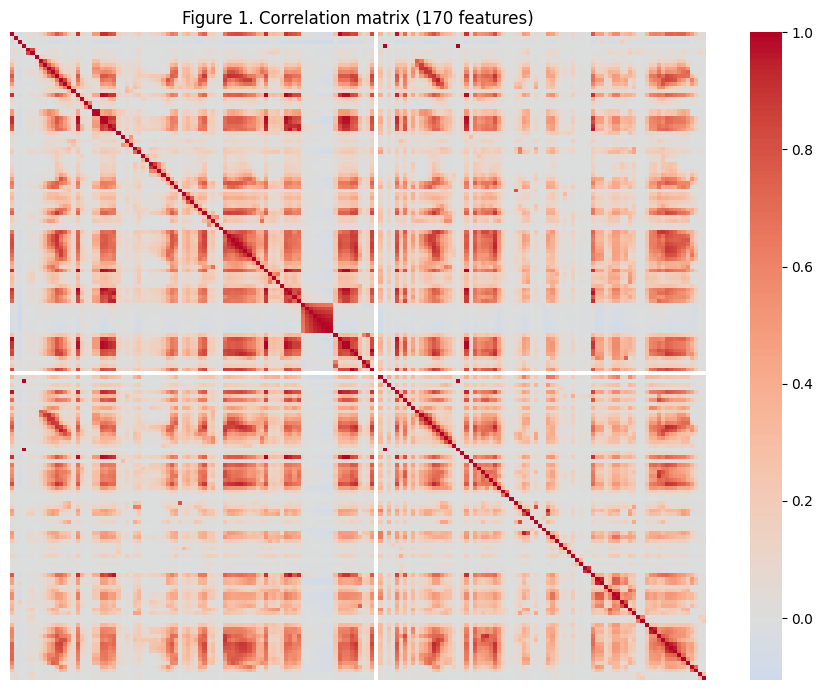

In [ ]:
plt.figure(figsize=(9, 7))
sns.heatmap(X_train.corr(), xticklabels=False, yticklabels=False, cmap='coolwarm', center=0)
plt.title('Figure 1. Correlation matrix (170 features)')
plt.tight_layout()
plt.show()

### (b)(iv)

Top 13: ['cf_000', 'co_000', 'ad_000', 'cs_009', 'dh_000', 'dj_000', 'ag_000', 'as_000', 'ay_009', 'ak_000', 'az_009', 'ch_000', 'au_000']


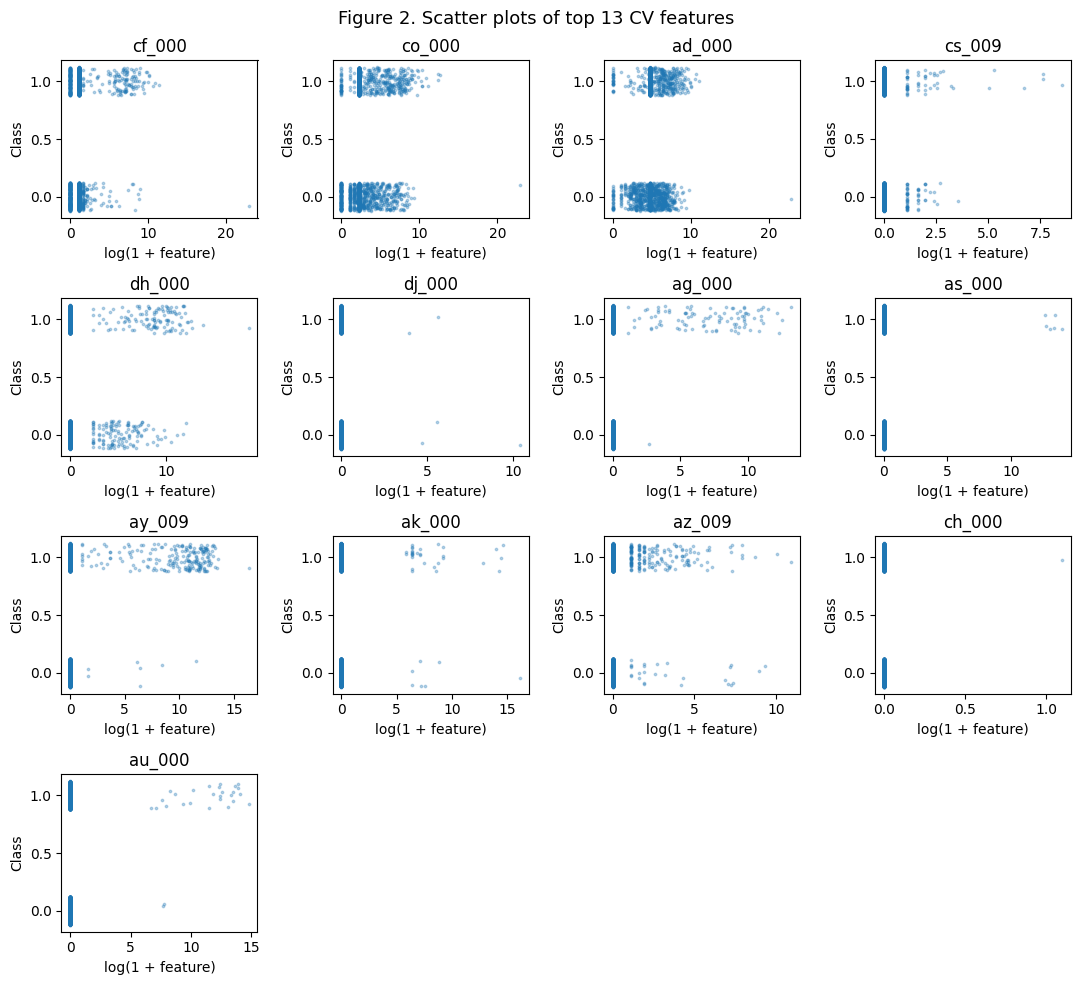

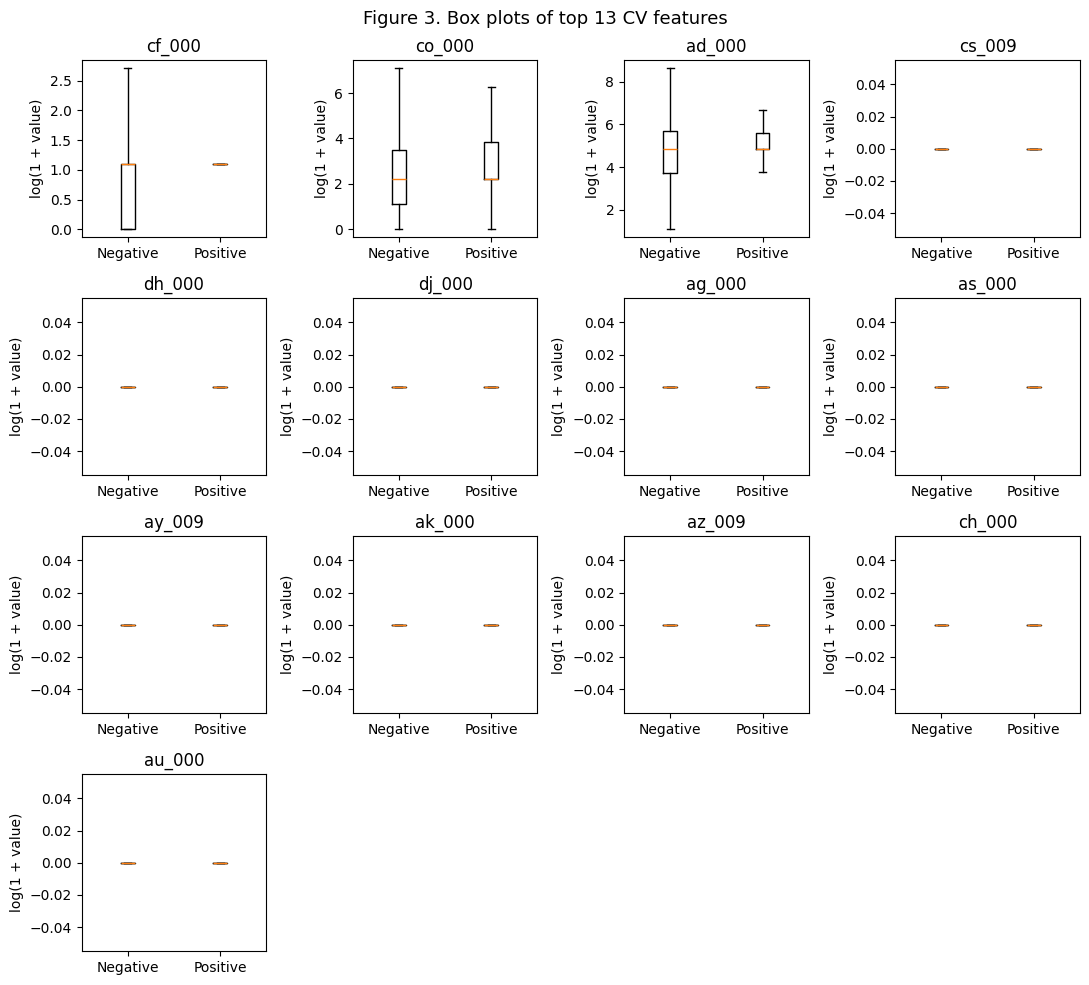

In [ ]:
top = cv.dropna().nlargest(13).index.tolist()
print('Top 13:', top)

rng = np.random.default_rng(RANDOM_STATE)
neg_idx = rng.choice(np.flatnonzero(y_train == 0), size=1000, replace=False)
idx = np.r_[neg_idx, np.flatnonzero(y_train == 1)]
fig, axes = plt.subplots(4, 4, figsize=(11, 10))
for ax, feature in zip(axes.flat, top):
    ax.scatter(np.log1p(X_train.iloc[idx][feature].clip(lower=0)),
               y_train.iloc[idx] + rng.uniform(-0.12, 0.12, len(idx)), s=3, alpha=0.3)
    ax.set(title=feature, xlabel='log(1 + feature)', ylabel='Class')
for ax in axes.flat[len(top):]: ax.axis('off')
fig.suptitle('Figure 2. Scatter plots of top 13 CV features', fontsize=13)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(4, 4, figsize=(11, 10))
for ax, feature in zip(axes.flat, top):
    values = np.log1p(X_train[feature].clip(lower=0))
    ax.boxplot([values[y_train == 0], values[y_train == 1]], showfliers=False)
    ax.set(title=feature, xticks=[1, 2], xticklabels=['Negative', 'Positive'], ylabel='log(1 + value)')
for ax in axes.flat[len(top):]: ax.axis('off')
fig.suptitle('Figure 3. Box plots of top 13 CV features', fontsize=13)
plt.tight_layout()
plt.show()

**Conclusion:** Scatter plots alone cannot prove feature significance.

### (b)(v)

In [ ]:
print('Training class counts (0=negative, 1=positive):')
print(y_train.value_counts().sort_index().to_string())
print('Positive proportion:', round(y_train.mean(), 4))
print('Imbalanced:', y_train.mean() < 0.1)

Training class counts (0=negative, 1=positive):
class
0    59000
1     1000
Positive proportion: 0.0167
Imbalanced: True


### (c)

Random Forest | Train | Error=0.0000, AUC=1.0000
Confusion matrix [TN FP; FN TP]: [[59000     0]
 [    1   999]]
Random Forest | Test | Error=0.0076, AUC=0.9927
Confusion matrix [TN FP; FN TP]: [[15610    15]
 [  106   269]]


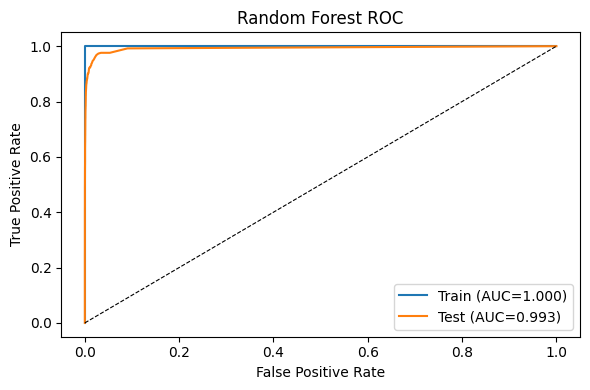

OOB error: 0.0062 | Test error: 0.0076


In [ ]:
def evaluate(name, model, Xtr, Xte):
    results = {}
    plt.figure(figsize=(6, 4))
    for label, X, y in [('Train', Xtr, y_train), ('Test', Xte, y_test)]:
        pred = model.predict(X)
        prob = model.predict_proba(X)[:, 1]
        auc = roc_auc_score(y, prob)
        error = 1 - accuracy_score(y, pred)
        results[label.lower() + '_error'] = error
        results[label.lower() + '_auc'] = auc
        print(f'{name} | {label} | Error={error:.4f}, AUC={auc:.4f}')
        print('Confusion matrix [TN FP; FN TP]:', confusion_matrix(y, pred))
        fpr, tpr, _ = roc_curve(y, prob)
        plt.plot(fpr, tpr, label=f'{label} (AUC={auc:.3f})')
    plt.plot([0, 1], [0, 1], 'k--', linewidth=0.8)
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title(name + ' ROC')
    plt.legend()
    plt.tight_layout()
    plt.show()
    return results

rf = RandomForestClassifier(n_estimators=100, oob_score=True, random_state=RANDOM_STATE, n_jobs=3)
rf.fit(X_train, y_train)
rf_results = evaluate('Random Forest', rf, X_train, X_test)
print('OOB error:', round(1 - rf.oob_score_, 4), '| Test error:', round(rf_results['test_error'], 4))

### (d)

Class imbalance is handled using balanced_subsample.

Balanced Random Forest | Train | Error=0.0000, AUC=1.0000
Confusion matrix [TN FP; FN TP]: [[59000     0]
 [    1   999]]
Balanced Random Forest | Test | Error=0.0108, AUC=0.9907
Confusion matrix [TN FP; FN TP]: [[15612    13]
 [  159   216]]


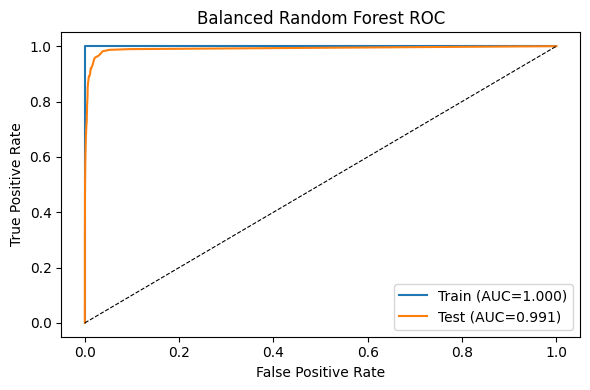

OOB error: 0.0079 | Test error: 0.0108
Test error (unbalanced, balanced): 0.0076 0.0108
Test AUC (unbalanced, balanced): 0.9927 0.9907


In [ ]:
rf_bal = RandomForestClassifier(n_estimators=100, class_weight='balanced_subsample',
                                oob_score=True, random_state=RANDOM_STATE, n_jobs=3)
rf_bal.fit(X_train, y_train)
rf_bal_results = evaluate('Balanced Random Forest', rf_bal, X_train, X_test)
print('OOB error:', round(1 - rf_bal.oob_score_, 4), '| Test error:', round(rf_bal_results['test_error'], 4))
print('Test error (unbalanced, balanced):', round(rf_results['test_error'], 4), round(rf_bal_results['test_error'], 4))
print('Test AUC (unbalanced, balanced):', round(rf_results['test_auc'], 4), round(rf_bal_results['test_auc'], 4))

### (e)

`reg_alpha` controls L1 regularization.

Best alpha: 10
5-fold CV AUC: 0.9876
5-fold CV error: 0.0085
XGBoost | Train | Error=0.0065, AUC=0.9930
Confusion matrix [TN FP; FN TP]: [[58891   109]
 [  280   720]]


XGBoost | Test | Error=0.0099, AUC=0.9947
Confusion matrix [TN FP; FN TP]: [[15595    30]
 [  129   246]]


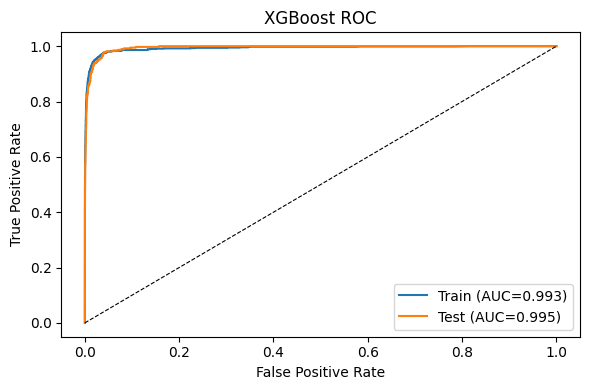

CV error vs test error: 0.0085 0.0099


In [ ]:
def xgb_model():
    return XGBClassifier(n_estimators=70, max_depth=3, learning_rate=0.12,
                         objective='binary:logistic', eval_metric='logloss',
                         tree_method='hist', n_jobs=3, random_state=RANDOM_STATE)

folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
base_pipe = SkPipeline([('imputer', SimpleImputer(strategy='median')), ('xgb', xgb_model())])
search = GridSearchCV(base_pipe, {'xgb__reg_alpha': [0.1, 1, 10]}, cv=folds,
                      scoring={'auc': 'roc_auc', 'accuracy': 'accuracy'},
                      refit='auc', n_jobs=1)
search.fit(X_train_raw, y_train)
print('Best alpha:', search.best_params_['xgb__reg_alpha'])
print('5-fold CV AUC:', round(search.best_score_, 4))
print('5-fold CV error:', round(1 - search.cv_results_['mean_test_accuracy'][search.best_index_], 4))
xgb_results = evaluate('XGBoost', search.best_estimator_, X_train_raw, X_test_raw)
print('CV error vs test error:', round(1 - search.cv_results_['mean_test_accuracy'][search.best_index_], 4),
      round(xgb_results['test_error'], 4))

### (f)

SMOTE is applied within training folds.

Best alpha: 0.1
5-fold CV AUC: 0.984
5-fold CV error: 0.0233
SMOTE + XGBoost | Train | Error=0.0228, AUC=0.9936
Confusion matrix [TN FP; FN TP]: [[57690  1310]
 [   60   940]]


SMOTE + XGBoost | Test | Error=0.0217, AUC=0.9936
Confusion matrix [TN FP; FN TP]: [[15302   323]
 [   24   351]]


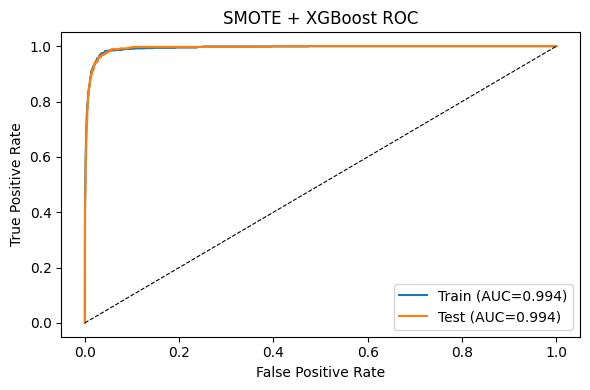

Test error (no SMOTE, SMOTE): 0.0099 0.0217
Test AUC (no SMOTE, SMOTE): 0.9947 0.9936


In [ ]:
smote_pipe = ImbPipeline([('imputer', SimpleImputer(strategy='median')),
                          ('smote', SMOTE(random_state=RANDOM_STATE)),
                          ('xgb', xgb_model())])
smote_search = GridSearchCV(smote_pipe, {'xgb__reg_alpha': [0.1, 1, 10]}, cv=folds,
                            scoring={'auc': 'roc_auc', 'accuracy': 'accuracy'},
                            refit='auc', n_jobs=1)
smote_search.fit(X_train_raw, y_train)
print('Best alpha:', smote_search.best_params_['xgb__reg_alpha'])
print('5-fold CV AUC:', round(smote_search.best_score_, 4))
print('5-fold CV error:', round(1 - smote_search.cv_results_['mean_test_accuracy'][smote_search.best_index_], 4))
smote_results = evaluate('SMOTE + XGBoost', smote_search.best_estimator_, X_train_raw, X_test_raw)
print('Test error (no SMOTE, SMOTE):', round(xgb_results['test_error'], 4), round(smote_results['test_error'], 4))
print('Test AUC (no SMOTE, SMOTE):', round(xgb_results['test_auc'], 4), round(smote_results['test_auc'], 4))

## 2. ISLR 6.6.3

(a) **iv**： Training RSS decreases.  
(b) **ii**： Test RSS decreases first, then increases.  
(c) **iii**： Variance increases.  
(d) **iv**： Bias² decreases.  
(e) **v**： Irreducible error stays the same.

## 3. ISLR 6.6.5


**(a) Ridge:**
$$\min_{\beta_1,\beta_2}\;2[y-a(\beta_1+\beta_2)]^2+\lambda(\beta_1^2+\beta_2^2).$$

**(b)** when $\boxed{\hat\beta_1=\hat\beta_2}$. In fact, $\hat\beta_1=\hat\beta_2=2ay/(4a^2+\lambda)$.

**(c) Lasso:**
$$\min_{\beta_1,\beta_2}\;2[y-a(\beta_1+\beta_2)]^2+\lambda(|\beta_1|+|\beta_2|).$$

**(d)** Lasso can have different coefficients with the same sum. So the solution is not always unique.

## 4. ISLR 8.4.5

Majority vote: Red (6 out of 10)

Average probability: Green (Red = 0.45).

## 5. ISLR 9.7.3

(a)
Boundary: \(X_2=X_1-0.5\)

(b)Red: above the line.

(c)Blue: below the line.

(d)Margins: \(X_2=X_1\) and \(X_2=X_1-1\).

(e)Support vectors: 2, 3, 5, 6.

(f) Point 7 is not a support vector. Small changes do not affect the line.  
(g) Another separating line: \(X_2=X_1-0.25\).

(h) Add a Red point at (3, 2). The data cannot be separated by a straight line.

Support vectors (1-based): [np.int32(2), np.int32(3), np.int32(5), np.int32(6)]


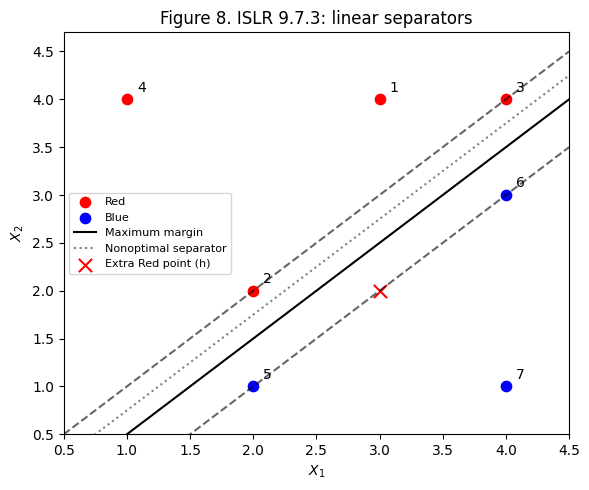

In [ ]:
points = np.array([[3,4], [2,2], [4,4], [1,4], [2,1], [4,3], [4,1]])
colors = np.array(['red'] * 4 + ['blue'] * 3)
svm = SVC(kernel='linear', C=10).fit(points, np.array([1]*4 + [0]*3))
print('Support vectors (1-based):', sorted(svm.support_ + 1))
x = np.linspace(0.5, 4.5, 100)
plt.figure(figsize=(6, 5))
for c in ['red', 'blue']:
    v = colors == c
    plt.scatter(points[v, 0], points[v, 1], c=c, label=c.title(), s=55)
for i, (a, b) in enumerate(points):
    plt.annotate(str(i + 1), (a + 0.08, b + 0.08))
plt.plot(x, x - .5, color='black', label='Maximum margin')
plt.plot(x, x, 'k--', alpha=.6)
plt.plot(x, x - 1, 'k--', alpha=.6)
plt.plot(x, x - .25, ':', color='gray', label='Nonoptimal separator')
plt.scatter([3], [2], marker='x', c='red', s=90, label='Extra Red point (h)')
plt.xlim(.5, 4.5); plt.ylim(.5, 4.7)
plt.xlabel('$X_1$'); plt.ylabel('$X_2$')
plt.title('Figure 8. ISLR 9.7.3: linear separators')
plt.legend(fontsize=8)
plt.tight_layout()
plt.show()

## References



*   ISLR
*   UCI APS
*   Scikit-learn
*   XGBoost
*   ChatGPT
*   Imbalanced-learn





